# Spaceship Titanic - Preprocesamiento y Red Neuronal

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
ruta_train = "/mnt/c/Users/bruno/SistemasInteligentes/data_tarea/train.csv"
ruta_test = "/mnt/c/Users/bruno/SistemasInteligentes/data_tarea/test.csv"
ruta_sample = "/mnt/c/Users/bruno/SistemasInteligentes/data_tarea/sample_submission.csv"
ruta_salida_submission = "/mnt/c/Users/bruno/SistemasInteligentes/data_tarea/submission.csv"

df = pd.read_csv(ruta_train)
df_test = pd.read_csv(ruta_test)
sample_sub = pd.read_csv(ruta_sample)

df.head(5)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [4]:
def plot_learning_curve(history):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()

# Tratamiento

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 1.2+ MB


In [6]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [7]:
spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

def preparar_filas(data):
    data = data.copy()
    
    cabin_parts = data["Cabin"].str.split("/", expand=True)
    data["Deck"] = cabin_parts[0]
    data["Side"] = cabin_parts[2]
    
    data = data.drop(columns=["PassengerId", "Name", "Cabin"])
    return data

df_proc = preparar_filas(df)
df_test_proc = preparar_filas(df_test)

In [9]:
todos_grupos = pd.concat([df["PassengerId"], df_test["PassengerId"]]).str.split("_").str[0]
conteo_grupos = todos_grupos.value_counts()

df_proc["GroupSize"] = df["PassengerId"].str.split("_").str[0].map(conteo_grupos)
df_proc["IsAlone"] = (df_proc["GroupSize"] == 1).astype(int)

df_test_proc["GroupSize"] = df_test["PassengerId"].str.split("_").str[0].map(conteo_grupos)
df_test_proc["IsAlone"] = (df_test_proc["GroupSize"] == 1).astype(int)

In [10]:
df_proc.isna().sum()[df_proc.isna().sum() > 0] / df_proc.shape[0] * 100

HomePlanet      2.312205
CryoSleep       2.496261
Destination     2.093639
Age             2.059128
VIP             2.335212
RoomService     2.082135
FoodCourt       2.105142
ShoppingMall    2.392730
Spa             2.105142
VRDeck          2.162660
Deck            2.289198
Side            2.289198
dtype: float64

In [11]:
df_proc.head(5)

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Deck,Side,GroupSize,IsAlone
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B,P,1,1
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F,S,1,1
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,A,S,2,0
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A,S,2,0
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F,S,1,1


In [12]:
X = df_proc.drop("Transported", axis=1)
y = df_proc["Transported"].astype(int)

In [13]:
y.value_counts() / df_proc.shape[0] * 100

Transported
1    50.362361
0    49.637639
Name: count, dtype: float64

In [14]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

In [15]:
print("Distribución Train (%):")
print(y_train.value_counts() / X_train.shape[0] * 100)
print("\nDistribución Val (%):")
print(y_val.value_counts() / X_val.shape[0] * 100)

Distribución Train (%):
Transported
1    50.369762
0    49.630238
Name: count, dtype: float64

Distribución Val (%):
Transported
1    50.345092
0    49.654908
Name: count, dtype: float64


In [16]:
raw_num_cols = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
cat_cols = ["HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side"]

for col in raw_num_cols:
    mediana = X_train[col].median()
    X_train[col] = X_train[col].fillna(mediana)
    X_val[col] = X_val[col].fillna(mediana)
    df_test_proc[col] = df_test_proc[col].fillna(mediana)

for d in [X_train, X_val, df_test_proc]:
    d["TotalSpend"] = d[spend_cols].sum(axis=1)
    d["NoSpend"] = (d["TotalSpend"] == 0).astype(int)

In [17]:
for col in cat_cols:
    moda = X_train[col].mode().iloc[0]
    X_train[col] = X_train[col].fillna(moda)
    X_val[col] = X_val[col].fillna(moda)
    df_test_proc[col] = df_test_proc[col].fillna(moda)

for col in ["CryoSleep", "VIP"]:
    X_train[col] = X_train[col].astype(int)
    X_val[col] = X_val[col].astype(int)
    df_test_proc[col] = df_test_proc[col].astype(int)

In [18]:
ohe_cols = ["HomePlanet", "Destination", "Deck", "Side"]
X_train = pd.get_dummies(X_train, columns=ohe_cols, dtype=int)
X_val = pd.get_dummies(X_val, columns=ohe_cols, dtype=int)
df_test_proc = pd.get_dummies(df_test_proc, columns=ohe_cols, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
df_test_proc = df_test_proc.reindex(columns=X_train.columns, fill_value=0)

X_train.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,GroupSize,IsAlone,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
3395,1,28.0,0,0.0,0.0,0.0,0.0,0.0,1,1,...,0,0,0,0,0,0,1,0,0,1
7906,0,32.0,0,0.0,2154.0,0.0,9655.0,859.0,2,0,...,0,0,1,0,0,0,0,0,0,1
1760,0,31.0,0,0.0,1983.0,0.0,172.0,52.0,1,1,...,0,0,1,0,0,0,0,0,0,1
1704,1,25.0,0,0.0,0.0,0.0,0.0,0.0,2,0,...,0,0,0,0,0,0,1,0,0,1
8025,0,26.0,0,6.0,728.0,0.0,1273.0,1116.0,1,1,...,0,0,0,1,0,0,0,0,1,0


In [19]:
num_cols = raw_num_cols + ["TotalSpend", "GroupSize"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
df_test_proc[num_cols] = scaler.transform(df_test_proc[num_cols])

print("Shape final de entrada:", X_train.shape)

Shape final de entrada: (6085, 28)


# Modelo y Evaluación

In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units=32, activation="relu"),
    tf.keras.layers.Dense(units=16, activation="relu"),
    tf.keras.layers.Dense(units=1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=["accuracy", tf.keras.metrics.F1Score(threshold=0.5)]
)

In [23]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=500,
    batch_size=32,
    verbose=1
)

Epoch 1/500
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8350 - f1_score: 0.8373 - loss: 0.3445 - val_accuracy: 0.7872 - val_f1_score: 0.7798 - val_loss: 0.4626
Epoch 2/500
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8345 - f1_score: 0.8368 - loss: 0.3440 - val_accuracy: 0.7883 - val_f1_score: 0.7816 - val_loss: 0.4625
Epoch 3/500
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8347 - f1_score: 0.8370 - loss: 0.3436 - val_accuracy: 0.7880 - val_f1_score: 0.7805 - val_loss: 0.4639
Epoch 4/500
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8343 - f1_score: 0.8362 - loss: 0.3432 - val_accuracy: 0.7883 - val_f1_score: 0.7813 - val_loss: 0.4642
Epoch 5/500
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8337 - f1_score: 0.8357 - loss: 0.3427 - val_accuracy: 0.7887 - val_f1_score: 0.7825 - val_loss: 0.4639
Epoch 6/500
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8345 - f1_score: 0.8367 - loss: 0.3425 - val_accuracy: 0.7895 - val_f1_score: 

# Gráficas de perdida y accuracy, junto con matriz de confusión

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


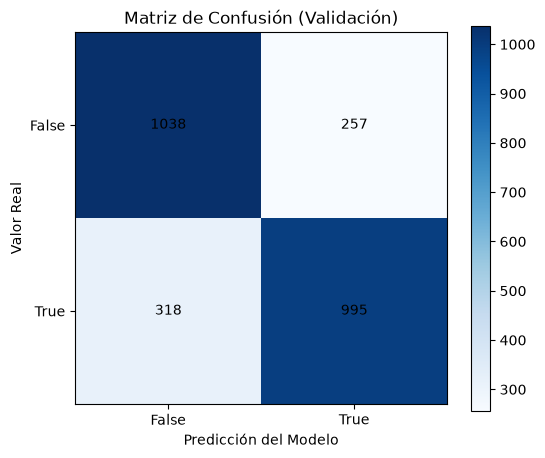

In [24]:
y_val_pred = (model.predict(X_val) > 0.5).astype(int)
matriz_confusion = tf.math.confusion_matrix(labels=y_val, predictions=y_val_pred).numpy()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(matriz_confusion, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, matriz_confusion[i, j], ha="center", va="center", color="black")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["False", "True"])
ax.set_yticklabels(["False", "True"])
ax.set_xlabel("Predicción del Modelo")
ax.set_ylabel("Valor Real")
ax.set_title("Matriz de Confusión (Validación)")
plt.colorbar(im)
plt.show()

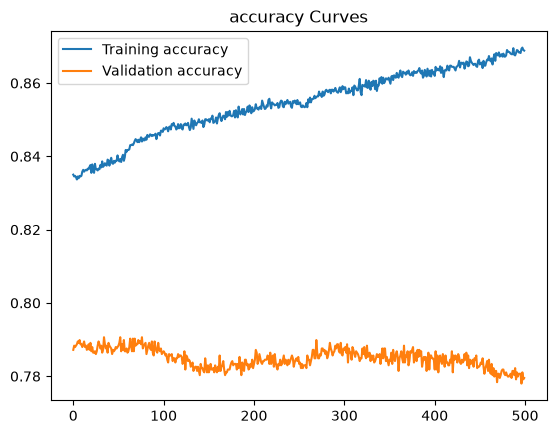

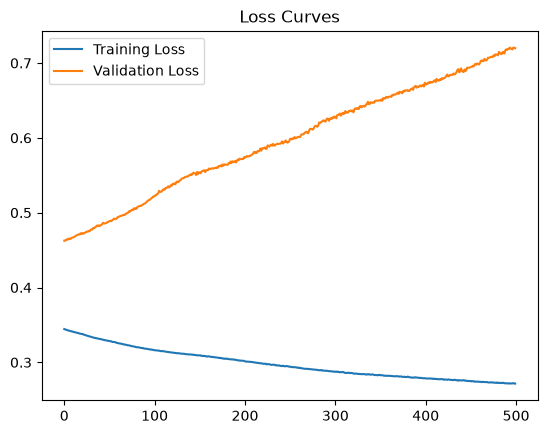

In [25]:
plot_learning_curve(history)

# Predicción Final y Generación de Submission

In [26]:
predicciones_test = (model.predict(df_test_proc) > 0.5).flatten()

submission = sample_sub.copy()
submission["Transported"] = predicciones_test
submission.to_csv(ruta_salida_submission, index=False)

print(f"Archivo guardado en: {ruta_salida_submission}")
submission.head()

134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
Archivo guardado en: /mnt/c/Users/bruno/SistemasInteligentes/data_tarea/submission.csv


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False
